In [35]:

import os
import random
import json
import pandas as pd
import numpy as np
import cv2
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import matplotlib.pyplot as plt
from collections import Counter
import matplotlib.patches as patches

# Set seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Check device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🔧 Using device: {device}")
if torch.cuda.is_available():
    print(f"   GPU: {torch.cuda.get_device_name(0)}")




🔧 Using device: cuda
   GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [36]:
BASE_DIR = '.'
df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")
df_sample_submission = pd.read_csv("sample_submission.csv")

# EDA

Number of training images in COCO: 750
Number of annotations: 1509
Categories: ['Images', 'entete', 'vin']
Annotation counts per category:
  vin: 755
  entete: 754


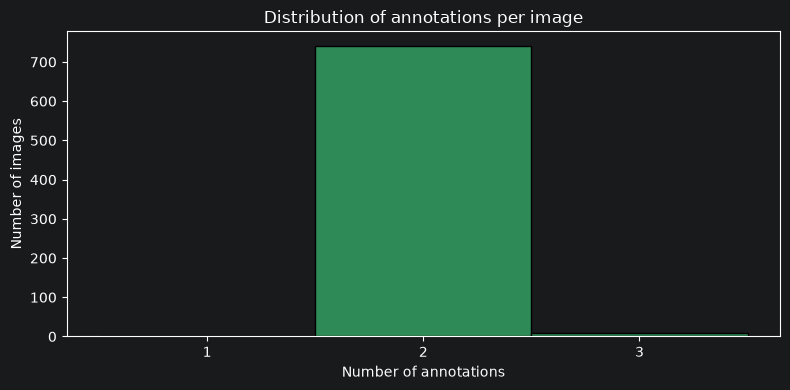

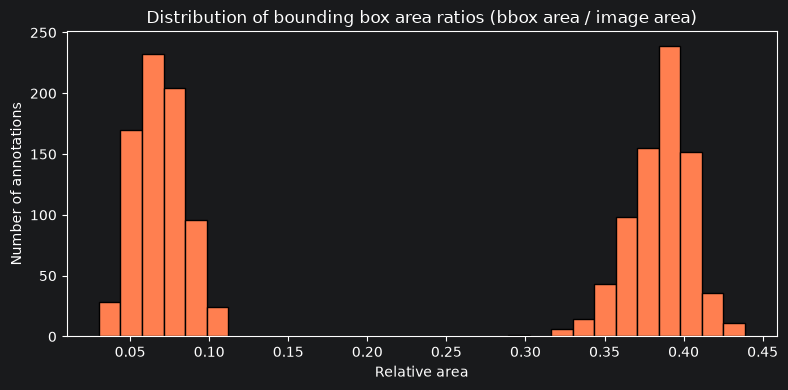

In [37]:
# Load COCO annotations for bounding boxes
annotations_path = os.path.join(BASE_DIR, 'train', '_annotations.coco.json')
with open(annotations_path, 'r', encoding='utf-8') as f:
    coco = json.load(f)

images = coco['images']
annotations = coco['annotations']
categories = coco['categories']

print(f'Number of training images in COCO: {len(images)}')
print(f'Number of annotations: {len(annotations)}')
print('Categories:', [cat['name'] for cat in categories])

category_counts = Counter()
annotations_per_image = Counter()
area_ratios = []
image_dim = {img['id']: (img['width'], img['height']) for img in images}

for ann in annotations:
    category_counts[ann['category_id']] += 1
    annotations_per_image[ann['image_id']] += 1
    bbox = ann['bbox']
    img_w, img_h = image_dim[ann['image_id']]
    area_ratios.append((bbox[2] * bbox[3]) / (img_w * img_h))

id_to_cat = {cat['id']: cat['name'] for cat in categories}
print('Annotation counts per category:')
for cat_id, count in category_counts.items():
    print(f'  {id_to_cat[cat_id]}: {count}')

# Plot distribution of annotations per image
plt.figure(figsize=(8,4))
plt.hist(list(annotations_per_image.values()), bins=range(1, max(annotations_per_image.values()) + 2),
         color='seagreen', edgecolor='black', align='left')
plt.title('Distribution of annotations per image')
plt.xlabel('Number of annotations')
plt.ylabel('Number of images')
plt.xticks(range(1, max(annotations_per_image.values()) + 1))
plt.tight_layout()
plt.show()

# Plot distribution of bounding box area ratios
plt.figure(figsize=(8,4))
plt.hist(area_ratios, bins=30, color='coral', edgecolor='black')
plt.title('Distribution of bounding box area ratios (bbox area / image area)')
plt.xlabel('Relative area')
plt.ylabel('Number of annotations')
plt.tight_layout()
plt.show()

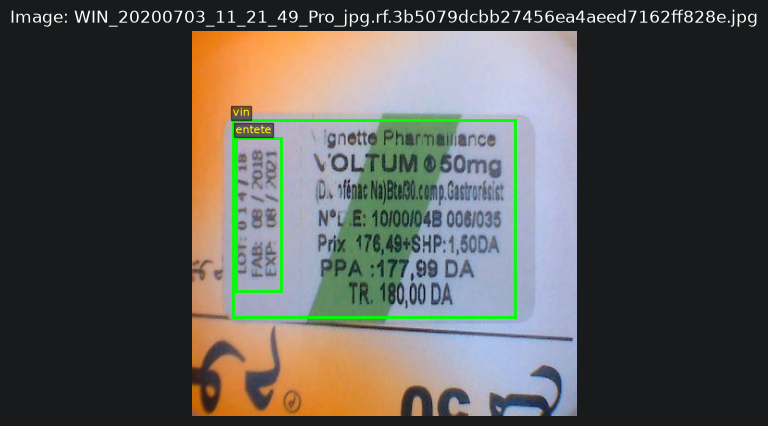

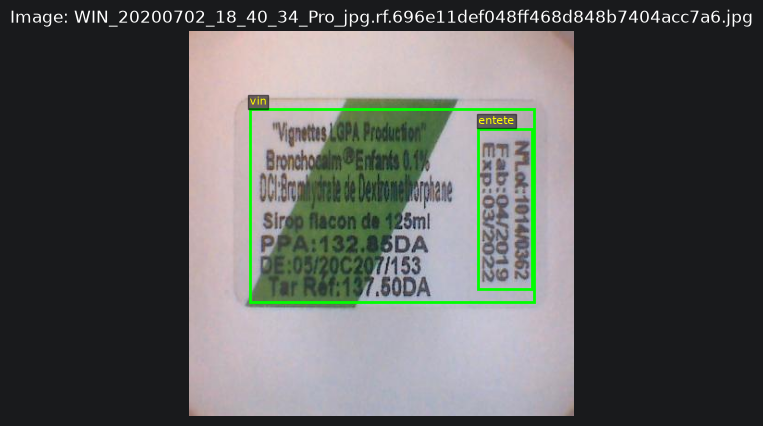

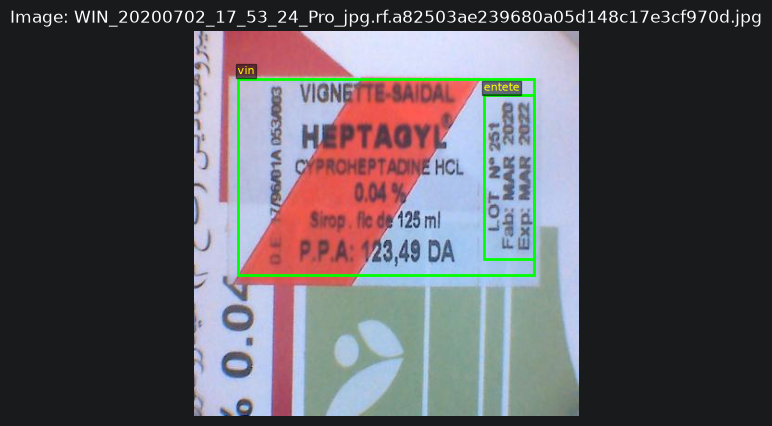

In [38]:
# Visualize random training images with bounding boxes
n_samples = 3
sample_images = random.sample(images, n_samples)

for img_info in sample_images:
    img_id = img_info['id']
    file_name = img_info['file_name']
    img_path = os.path.join(BASE_DIR, 'train', file_name)
    img = Image.open(img_path).convert('RGB')
    fig, ax = plt.subplots(1,1, figsize=(5,5))
    ax.imshow(img)
    for ann in annotations:
        if ann['image_id'] == img_id:
            bbox = ann['bbox']
            rect = patches.Rectangle((bbox[0], bbox[1]), bbox[2], bbox[3],
                                     linewidth=2, edgecolor='lime', facecolor='none')
            ax.add_patch(rect)
            cat_name = id_to_cat[ann['category_id']]
            ax.text(bbox[0], max(bbox[1] - 5, 0), cat_name, color='yellow', fontsize=8,
                    bbox=dict(facecolor='black', alpha=0.5, pad=1))
    ax.set_title(f'Image: {file_name}')
    ax.axis('off')
    plt.show()

8# STARTER

In [39]:
id_column = df_sample_submission.columns[0]
target_column = df_sample_submission.columns[1]

placeholder_text = 'recognized-text'.upper()
predictions = np.full(len(df_test), placeholder_text)

In [40]:
submission_df = pd.DataFrame({
    id_column: df_test[id_column], # Use the ID column from the test data
    target_column: predictions
})

# Crucially, save the file as 'submission.csv' to the working directory.
# The `index=False` argument is essential to prevent pandas from writing row numbers.
submission_df.to_csv('submission.csv', index=False)

print("\nSuccessfully created submission.csv!")
print("Submission Head:")
print(submission_df.head())


Successfully created submission.csv!
Submission Head:
                                     id             text
0  0016f1ad9e7f16aa6dd2b8c9c13cb922.jpg  RECOGNIZED-TEXT
1  005e28f75a93bc4de0e9e11373bdca47.jpg  RECOGNIZED-TEXT
2  007f7b00eb0a66cabcd72007358e3660.jpg  RECOGNIZED-TEXT
3  009a43c2870949af417f769b90ee20cf.jpg  RECOGNIZED-TEXT
4  014d3d8a2ef0d4deb88a83357781745c.jpg  RECOGNIZED-TEXT


# BASELINE PROTOKOL

In [41]:
import argparse
import json
import random
import re
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np
import pandas as pd

TS_RE = re.compile(r"WIN_(\d{8})_(\d{2})_(\d{2})_(\d{2})")

In [42]:

def parse_ts(name):
    """'WIN_20200702_14_56_08_Pro...' -> datetime; None jika pola tidak cocok."""
    m = TS_RE.search(name)
    return datetime.strptime("".join(m.groups()), "%Y%m%d%H%M%S") if m else None


def largest(boxes):
    """Dari beberapa kotak [x, y, w, h], ambil yang terluas (None jika kosong)."""
    return max(boxes, key=lambda b: b[2] * b[3]) if boxes else None


def load_coco(path):
    coco = json.load(open(annotations_path, encoding="utf-8"))
    cat_name = {c["id"]: c["name"] for c in coco["categories"]}  # petakan per NAMA, bukan indeks
    per_img = {}
    for a in coco["annotations"]:
        per_img.setdefault(a["image_id"], {}).setdefault(cat_name[a["category_id"]], []).append(a["bbox"])
    rows = []
    for im in coco["images"]:
        boxes = per_img.get(im["id"], {})
        rows.append(dict(
            image_id=im["id"], file_name=im["file_name"], width=im["width"], height=im["height"],
            ts=parse_ts(im["file_name"]),
            n_entete=len(boxes.get("entete", [])),
            entete=largest(boxes.get("entete", [])), vin=largest(boxes.get("vin", [])),
        ))
    return pd.DataFrame(rows)


def blocked_split(df, block_size=30, val_frac=0.2, seed=42):
    """
    Urutkan menurut waktu, potong jadi blok berurutan, lalu acak PER BLOK.
    Frame yang berdekatan waktunya selalu masuk split yang sama -> mengurangi kebocoran.
    """
    df = df.sort_values(["ts", "file_name"], na_position="first").reset_index(drop=True)
    df["block"] = np.arange(len(df)) // block_size
    blocks = sorted(df["block"].unique())
    val_blocks = set(random.Random(seed).sample(blocks, max(1, round(len(blocks) * val_frac))))
    df["split"] = np.where(df["block"].isin(val_blocks), "val", "train")
    return df


def crop_box(img, box, pad=0.08):
    """Potong kotak [x, y, w, h] dengan padding relatif; jika tegak, putar 90 deg agar horizontal."""
    H, W = img.shape[:2]
    x, y, w, h = box
    x1, y1 = max(0, int(x - pad * w)), max(0, int(y - pad * h))
    x2, y2 = min(W, int(x + w + pad * w)), min(H, int(y + h + pad * h))
    crop = img[y1:y2, x1:x2]
    if crop.shape[0] > crop.shape[1]:
        crop = np.ascontiguousarray(np.rot90(crop))
    return crop


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--coco", required=True)
    ap.add_argument("--images_dir", default=None, help="default: folder file COCO")
    ap.add_argument("--out_dir", required=True)
    ap.add_argument("--block_size", type=int, default=30)
    ap.add_argument("--val_frac", type=float, default=0.2)
    ap.add_argument("--n_gold", type=int, default=80)
    ap.add_argument("--seed", type=int, default=42)
    a = ap.parse_args(argv)

    images_dir = Path(a.images_dir) if a.images_dir else Path(a.coco).parent
    out = Path(a.out_dir)
    (out / "crops").mkdir(parents=True, exist_ok=True)

    df = blocked_split(load_coco(a.coco), a.block_size, a.val_frac, a.seed)

    crop_paths = []
    for r in df.itertuples():
        img = cv2.imread(str(images_dir / r.file_name))
        if img is None or r.entete is None:        # catat, jangan hilang diam-diam
            crop_paths.append("")
            continue
        p = out / "crops" / (Path(r.file_name).stem + ".png")
        cv2.imwrite(str(p), crop_box(img, r.entete))
        crop_paths.append(str(p))
    df["crop_path"] = crop_paths
    df.to_csv(out / "meta.csv", index=False)

    val = df[(df["split"] == "val") & (df["crop_path"] != "")]
    gold = val.sample(min(a.n_gold, len(val)), random_state=a.seed)[["file_name", "crop_path"]]
    gold = gold.rename(columns={"file_name": "id"}).assign(verified_text="")
    gold.to_csv(out / "gold_candidates.csv", index=False)

    print(df.groupby("split").size().to_string())
    print("gambar tanpa entete:", int((df["entete"].isna()).sum()),
          "| gambar dengan >1 entete:", int((df["n_entete"] > 1).sum()),
          "| crop gagal:", int((df["crop_path"] == "").sum()))
    print("gold candidates:", len(gold))

import phase0_prepare as p
p.main(["--coco", "train/_annotations.coco.json", "--out_dir", "phase0"])


split
train    600
val      150
gambar tanpa entete: 0 | gambar dengan >1 entete: 4 | crop gagal: 0
gold candidates: 80


# YOLO + EASYOCR

Alur: **YOLO** mendeteksi kotak `entete` pada gambar → kotak dipotong (crop) → **EasyOCR** membaca isi crop → teks dibersihkan ke format submission.

- `MODE = 'yolo'` (utama): deteksi `entete` lalu OCR crop. Jika YOLO tidak menemukan `entete`, gambar itu otomatis di-OCR penuh sebagai cadangan.
- `MODE = 'full'`: tanpa YOLO, EasyOCR membaca seluruh gambar lalu memilih satu baris teks (pembanding).

Hasil antara (deteksi YOLO, hasil OCR, crop) disimpan ke disk, sehingga ambang dan aturan teks bisa disetel ulang tanpa mengulang proses berat.

### Melanjutkan setelah terminate / restart kernel
Semua hasil berat sudah ada di disk: `yolo_data/`, `runs_yolo/` (checkpoint YOLO tiap epoch), `yolo_test_dets.json`, `ocr_yolo.json`, `test_crops/`, `submission.csv`. File JSON ditulis berkala dan atomik, juga saat sel di-interrupt, sehingga aman walau proses dimatikan paksa.

Setelah restart, jalankan: **(1)** sel imports di paling atas, sel `read_csv`, dan sel `id_column = ...`; **(2)** sel `# 1)`, `# 2)`, dan `# 2b)` (Status); **(3)** sel berikutnya yang ditunjukkan Status. Sel yang pekerjaannya sudah selesai akan langsung melewati bagian yang sudah ada.

**Jangan** menjalankan ulang sel starter yang menulis `submission.csv` berisi placeholder, karena akan menimpa hasil Anda.

In [43]:
# 1) EasyOCR + lokasi gambar test
try:
    import easyocr
except ImportError:
    %pip install -q easyocr
    import easyocr

import re, time, shutil
from datetime import datetime

DEVICE   = 0 if torch.cuda.is_available() else 'cpu'
ALLOWLIST = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789/-'      # sesuai aturan format submission
reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available())

TEST_DIR = next((os.path.join(BASE_DIR, d) for d in ['test', 'Test', os.path.join('images', 'test')]
                 if os.path.isdir(os.path.join(BASE_DIR, d))), None)
assert TEST_DIR is not None, "Folder gambar test tidak ditemukan. Atur TEST_DIR secara manual."

path_of = {}
for root, _, files in os.walk(TEST_DIR):
    for fn in files:
        path_of[fn] = os.path.join(root, fn)

ids = df_test[id_column].tolist()
missing = [i for i in ids if i not in path_of]
print(f"Folder test: {TEST_DIR} | id: {len(ids)} | gambar tidak ditemukan: {len(missing)}")
if missing:
    print("Contoh id hilang:", missing[:5])

Folder test: .\test | id: 674 | gambar tidak ditemukan: 0


In [44]:
# 2) Lokasi hasil di disk + fungsi bantu (definisi saja, tidak menjalankan proses berat)
YOLO_DIR    = os.path.abspath('yolo_data')
DATA_YAML   = os.path.join(YOLO_DIR, 'data.yaml')
RUN_DIR, RUN_NAME = os.path.abspath('runs_yolo'), 'entete_vin'
BEST        = os.path.join(RUN_DIR, RUN_NAME, 'weights', 'best.pt')
LAST        = os.path.join(RUN_DIR, RUN_NAME, 'weights', 'last.pt')
RESULTS_CSV = os.path.join(RUN_DIR, RUN_NAME, 'results.csv')
DET_PATH    = 'yolo_test_dets.json'
CROP_DIR    = 'test_crops'
IMGSZ       = 640

def save_json(obj, path):
    """Tulis atomik: file lama tidak rusak walau proses dimatikan di tengah penulisan."""
    tmp = path + '.tmp'
    with open(tmp, 'w', encoding='utf-8') as f:
        json.dump(obj, f)
    os.replace(tmp, path)

def load_json(path):
    if not os.path.exists(path):
        return {}
    try:
        with open(path, encoding='utf-8') as f:
            return json.load(f)
    except Exception as ex:
        os.replace(path, path + '.bak')
        print(f"[peringatan] {path} rusak ({ex}); dipindah ke {path}.bak, mulai dari kosong")
        return {}

def train_finished():
    """True bila training YOLO sudah selesai (checkpoint akhir ditandai epoch = -1)."""
    if not os.path.exists(LAST):
        return os.path.exists(BEST)
    try:
        return torch.load(LAST, map_location='cpu', weights_only=False).get('epoch') == -1
    except Exception:
        return False

_DASH  = str.maketrans({'–': '-', '—': '-', '‒': '-', '−': '-', '_': '-', '\\': '/'})
_VALID = re.compile(r'[^A-Z0-9/-]')

def clean_text(s):
    """Huruf besar; hanya A-Z, 0-9, '/' dan '-'; semua spasi/baris baru hilang."""
    return _VALID.sub('', s.translate(_DASH).upper())

def to_items(dets):
    items = []
    for d in dets:
        xs = [p[0] for p in d['box']]; ys = [p[1] for p in d['box']]
        x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys)
        w, h = x2 - x1, y2 - y1
        txt = clean_text(d['text'])
        items.append(dict(x1=x1, x2=x2, y1=y1, y2=y2, w=w, h=h, cx=(x1 + x2) / 2, cy=(y1 + y2) / 2,
                          vertical=(h > 1.5 * w and len(txt) >= 2), text=txt, conf=d['conf']))
    return [it for it in items if it['text']]

def merge_lines(items, y_tol=0.6, gap_tol=2.5):
    """Gabungkan potongan teks yang sebaris (EasyOCR sering memecah 'A23B/45' dan '-C99')."""
    lines = []
    for it in sorted([i for i in items if not i['vertical']], key=lambda i: i['cy']):
        for ln in lines:
            cy = np.mean([m['cy'] for m in ln]); hh = max(it['h'], np.mean([m['h'] for m in ln]))
            gap = min(max(0, it['x1'] - m['x2'], m['x1'] - it['x2']) for m in ln)
            if abs(it['cy'] - cy) < y_tol * hh and gap < gap_tol * hh:
                ln.append(it); break
        else:
            lines.append([it])
    out = []
    for ln in lines:
        ln = sorted(ln, key=lambda m: m['x1'])
        wts = [len(m['text']) for m in ln]
        out.append(dict(text=''.join(m['text'] for m in ln), cy=float(np.mean([m['cy'] for m in ln])),
                        conf=float(np.average([m['conf'] for m in ln], weights=wts))))
    out += [dict(text=i['text'], cy=i['cy'], conf=i['conf']) for i in items if i['vertical']]
    return out

def crop_text(dets, min_conf=0.15):
    """Isi crop `entete`: SEMUA baris dibaca atas->bawah lalu digabung tanpa spasi."""
    lines = merge_lines([it for it in to_items(dets) if it['conf'] >= min_conf])
    lines.sort(key=lambda l: l['cy'])
    return ''.join(l['text'] for l in lines).strip('/-')

def score_line(ln):
    t = ln['text']
    if len(t.strip('/-')) < 3:
        return 0.0
    s = ln['conf'] * min(len(t), 20)
    if any(c.isdigit() for c in t) and any(c in '/-' for c in t):   # pola khas ID: angka + pemisah
        s *= 1.5
    return s

def predict_text(dets):
    """Mode full-image / cadangan: pilih SATU baris terbaik dari seluruh gambar."""
    lines = merge_lines(to_items(dets))
    best = max(lines, key=score_line, default=None)
    if best is not None and score_line(best) > 0:
        return best['text'].strip('/-') or '0'
    return '0'

def crop_entete(img, xyxy, pad=0.08):
    """Potong kotak entete dengan padding; jika tegak, putar 90 derajat (sama seperti baseline)."""
    H, W = img.shape[:2]
    x1, y1, x2, y2 = xyxy; w, h = x2 - x1, y2 - y1
    a, b = max(0, int(x1 - pad * w)), max(0, int(y1 - pad * h))
    c, d = min(W, int(x2 + pad * w)), min(H, int(y2 + pad * h))
    crop = img[b:d, a:c]
    if crop.size == 0:
        return None
    if crop.shape[0] > crop.shape[1]:
        crop = np.ascontiguousarray(np.rot90(crop))
    long_side = max(crop.shape[:2])
    if long_side < 640:                                   # perbesar crop kecil agar mudah dibaca
        s = 640 / long_side
        crop = cv2.resize(crop, None, fx=s, fy=s, interpolation=cv2.INTER_CUBIC)
    return crop

In [45]:
# 2b) STATUS: seberapa jauh pekerjaan sudah tersimpan di disk (aman dijalankan kapan saja)
def _n(path):
    return len(load_json(path)) if os.path.exists(path) else 0

n_valid  = sum(i in path_of for i in ids)
epochs   = max(0, sum(1 for _ in open(RESULTS_CSV)) - 1) if os.path.exists(RESULTS_CSV) else 0
n_det, n_ocr_y, n_ocr_f = _n(DET_PATH), _n('ocr_yolo.json'), _n('ocr_full.json')
done_train = train_finished()

print(f"Dataset YOLO    : {'ada' if os.path.exists(DATA_YAML) else 'belum ada'}")
print(f"Training YOLO   : {epochs} epoch tercatat | {'SELESAI' if done_train else 'belum selesai'}")
print(f"Deteksi test    : {n_det}/{n_valid}")
print(f"OCR mode yolo   : {n_ocr_y}/{len(ids)} | mode full: {n_ocr_f}/{len(ids)}")
print(f"Crop tersimpan  : {len(os.listdir(CROP_DIR)) if os.path.isdir(CROP_DIR) else 0}")
print(f"submission.csv  : {time.strftime('%Y-%m-%d %H:%M', time.localtime(os.path.getmtime('submission.csv'))) if os.path.exists('submission.csv') else 'belum ada'}")

if not done_train:
    nxt = "sel 4 (training; otomatis lanjut dari last.pt)" if os.path.exists(DATA_YAML) else "sel 3 lalu sel 4"
elif n_det < n_valid:
    nxt = "sel 4 (muat model), lalu sel 5 (deteksi; lanjut dari cache)"
elif n_ocr_y < len(ids):
    nxt = "sel 6 (OCR; lanjut dari cache), lalu sel 7"
else:
    nxt = "sel 7 (submission); semua tahap sudah selesai"
print("\nLangkah berikutnya:", nxt)

Dataset YOLO    : ada
Training YOLO   : 45 epoch tercatat | SELESAI
Deteksi test    : 674/674
OCR mode yolo   : 1424/674 | mode full: 0/674
Crop tersimpan  : 520
submission.csv  : 2026-10-24 11:35

Langkah berikutnya: sel 7 (submission); semua tahap sudah selesai


## YOLO: deteksi `entete` & `vin`

Anotasi COCO (`train/_annotations.coco.json`) diubah ke format YOLO. Split train/val memakai **blok waktu** seperti baseline (frame yang berdekatan waktunya tidak terpisah antara train dan val). Kelas: `entete` = 0, `vin` = 1 (kelas induk `Images` diabaikan). Hanya `entete` yang dipakai untuk OCR; `vin` ikut dilatih agar model terbiasa membedakan keduanya.

In [46]:
# 3) Konversi COCO -> format YOLO (split blok waktu). Dilewati bila data.yaml sudah ada.
REBUILD   = False
COCO_PATH = os.path.join(BASE_DIR, 'train', '_annotations.coco.json')
CLASSES   = ['entete', 'vin']
BLOCK, VAL_FRAC = 30, 0.2
_TS = re.compile(r"WIN_(\d{8})_(\d{2})_(\d{2})_(\d{2})")

def _ts(name):
    m = _TS.search(name)
    return datetime.strptime("".join(m.groups()), "%Y%m%d%H%M%S") if m else datetime.min

def build_yolo_dataset():
    coco = json.load(open(COCO_PATH, encoding='utf-8'))
    cls_of = {c['id']: CLASSES.index(c['name']) for c in coco['categories'] if c['name'] in CLASSES}
    anns = {}
    for a in coco['annotations']:
        if a['category_id'] in cls_of:
            anns.setdefault(a['image_id'], []).append(a)

    imgs_sorted = sorted(coco['images'], key=lambda im: (_ts(im['file_name']), im['file_name']))
    n_blocks = (len(imgs_sorted) + BLOCK - 1) // BLOCK
    val_blocks = set(random.Random(SEED).sample(range(n_blocks), max(1, round(n_blocks * VAL_FRAC))))

    if os.path.exists(YOLO_DIR):
        shutil.rmtree(YOLO_DIR)
    for sp in ('train', 'val'):
        os.makedirs(os.path.join(YOLO_DIR, 'images', sp))
        os.makedirs(os.path.join(YOLO_DIR, 'labels', sp))

    n_box, n_skip = Counter(), 0
    for k, im in enumerate(imgs_sorted):
        sp = 'val' if (k // BLOCK) in val_blocks else 'train'
        src = os.path.join(BASE_DIR, 'train', im['file_name'])
        if not os.path.exists(src):
            n_skip += 1
            continue
        shutil.copy2(src, os.path.join(YOLO_DIR, 'images', sp, os.path.basename(im['file_name'])))
        W, H = im['width'], im['height']
        rows = []
        for a in anns.get(im['id'], []):
            x, y, w, h = a['bbox']
            x1, y1, x2, y2 = max(0, x), max(0, y), min(W, x + w), min(H, y + h)
            if x2 - x1 <= 1 or y2 - y1 <= 1:
                continue
            rows.append(f"{cls_of[a['category_id']]} {(x1 + x2) / 2 / W:.6f} {(y1 + y2) / 2 / H:.6f} "
                        f"{(x2 - x1) / W:.6f} {(y2 - y1) / H:.6f}")
            n_box[(sp, CLASSES[cls_of[a['category_id']]])] += 1
        stem = os.path.splitext(os.path.basename(im['file_name']))[0]
        with open(os.path.join(YOLO_DIR, 'labels', sp, stem + '.txt'), 'w') as f:
            f.write("\n".join(rows))

    # data.yaml ditulis TERAKHIR: keberadaannya menandakan konversi selesai utuh
    with open(DATA_YAML, 'w') as f:
        f.write(f"path: {YOLO_DIR.replace(os.sep, '/')}\ntrain: images/train\nval: images/val\n"
                f"names:\n  0: entete\n  1: vin\n")

    print("Gambar train:", len(os.listdir(os.path.join(YOLO_DIR, 'images', 'train'))),
          "| val:", len(os.listdir(os.path.join(YOLO_DIR, 'images', 'val'))), "| file hilang:", n_skip)
    print("Jumlah kotak:", dict(n_box))

if os.path.exists(DATA_YAML) and not REBUILD:
    print("Dataset YOLO sudah ada, dilewati (set REBUILD = True untuk membuat ulang).")
else:
    build_yolo_dataset()

Dataset YOLO sudah ada, dilewati (set REBUILD = True untuk membuat ulang).


In [47]:
# 4) Latih YOLO. Otomatis: lanjut dari last.pt bila training terputus, dilewati bila sudah selesai.
try:
    import ultralytics
except ImportError:
    %pip install -q ultralytics
from ultralytics import YOLO

RETRAIN = False          # True = mulai ulang dari awal (menimpa hasil lama)

def fresh_train():
    YOLO('yolov8s.pt').train(
        data=DATA_YAML, epochs=60, patience=15, imgsz=IMGSZ, batch=8, device=DEVICE,
        project=RUN_DIR, name=RUN_NAME, exist_ok=True, seed=SEED,
        fliplr=0.0,                                   # teks tidak boleh dicerminkan
        workers=0 if os.name == 'nt' else 2)

if RETRAIN:
    fresh_train()
elif os.path.exists(LAST) and not train_finished():
    print("Training sebelumnya terputus -> dilanjutkan dari last.pt")
    YOLO(LAST).train(resume=True)                    # pengaturan & epoch dipulihkan dari checkpoint
elif not os.path.exists(BEST):
    assert os.path.exists(DATA_YAML), "Jalankan sel 3 (konversi dataset) dulu."
    fresh_train()
else:
    print("Training sudah selesai, memakai best.pt")

yolo = YOLO(BEST)
if os.path.exists(DATA_YAML):
    m = yolo.val(data=DATA_YAML, imgsz=IMGSZ, device=DEVICE, verbose=False)
    print(f"Validasi deteksi (bukan OCR) -> mAP50: {m.box.map50:.3f} | mAP50-95: {m.box.map:.3f}")

Training sudah selesai, memakai best.pt
Ultralytics 8.4.172  Python-3.13.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 268.856.0 MB/s, size: 25.0 KB)
val: Scanning C:\INAH-MINE\GEMASTIK-XIX\vignette-ocr\yolo_data\labels\val.cache... 150 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 35.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 1.9s/it 19.4s.3ss
                   all        150        304      0.996      0.983       0.99      0.883
Speed: 4.6ms preprocess, 13.7ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to C:\INAH-MINE\GEMASTIK-XIX\vignette-ocr\runs\detect\val-4
Validasi deteksi (bukan OCR) -> mAP50: 0.990 | mAP50-95: 0.883


In [48]:
# 5) Deteksi pada gambar test. Disimpan tiap 50 gambar dan saat di-interrupt; lanjut dari cache.
dets_cache = load_json(DET_PATH)
todo = [i for i in ids if i not in dets_cache and i in path_of]
print(f"Sudah di-cache: {len(dets_cache)} | akan dideteksi: {len(todo)}")

try:
    for n, img_id in enumerate(tqdm(todo), 1):
        img = cv2.imread(path_of[img_id])
        if img is None:
            dets_cache[img_id] = []
            continue
        r = yolo.predict(img, imgsz=IMGSZ, conf=0.01, max_det=10, device=DEVICE, verbose=False)[0]
        dets_cache[img_id] = [dict(cls=int(c), conf=round(float(p), 4), xyxy=[round(float(v), 1) for v in b])
                              for c, p, b in zip(r.boxes.cls.tolist(), r.boxes.conf.tolist(), r.boxes.xyxy.tolist())]
        if n % 50 == 0:
            save_json(dets_cache, DET_PATH)
finally:
    save_json(dets_cache, DET_PATH)                   # juga dijalankan saat sel di-interrupt

best_conf = [max([d['conf'] for d in dets_cache.get(i, []) if d['cls'] == 0], default=0.0) for i in ids]
print("Gambar tanpa entete sama sekali :", sum(c == 0 for c in best_conf))
print("Gambar dengan conf entete < 0.25 :", sum(0 < c < 0.25 for c in best_conf))

Sudah di-cache: 674 | akan dideteksi: 0


0it [00:00, ?it/s]

Gambar tanpa entete sama sekali : 107
Gambar dengan conf entete < 0.25 : 87


# OCR & submission

Untuk setiap gambar: ambil kotak `entete` dengan confidence tertinggi → crop → EasyOCR → **semua baris di dalam crop digabung** (atas ke bawah, tanpa spasi/baris baru). Jika tidak ada `entete` yang meyakinkan atau crop tidak menghasilkan teks, gambar itu di-OCR penuh sebagai cadangan.

In [49]:
# 6) EasyOCR pada crop entete. Disimpan tiap 50 gambar dan saat di-interrupt; lanjut dari cache.
MODE            = 'yolo'        # 'yolo' = crop entete hasil YOLO | 'full' = OCR seluruh gambar tanpa YOLO
ENTETE_MIN_CONF = 0.05          # kotak entete di bawah ini dianggap tidak ada -> OCR penuh
CROP_ROTATIONS  = [90, 180, 270]
FULL_ROTATIONS  = [90, 270]
os.makedirs(CROP_DIR, exist_ok=True)

dets_cache = load_json(DET_PATH)                       # dibaca dari disk: tidak perlu menjalankan sel 4-5 lagi
if MODE == 'yolo':
    need = [i for i in ids if i in path_of and i not in dets_cache]
    if need:
        raise RuntimeError(f"Deteksi YOLO belum lengkap ({len(need)} gambar). Jalankan sel 4 lalu sel 5, atau set MODE = 'full'.")

def choose_entete(dets):
    cands = [d for d in dets if d['cls'] == 0 and d['conf'] >= ENTETE_MIN_CONF]
    return max(cands, key=lambda d: d['conf'])['xyxy'] if cands else None

def run_ocr(img, rotations):
    try:
        res = reader.readtext(img, allowlist=ALLOWLIST, rotation_info=rotations or None,
                              detail=1, paragraph=False)
    except Exception as ex:
        print(f"[OCR gagal] {ex}")
        res = []
    return [dict(box=[[int(x), int(y)] for x, y in b], text=t, conf=float(c)) for b, t, c in res]

cache_path = f'ocr_{MODE}.json'
ocr_cache = load_json(cache_path)
print(f"OCR sudah di-cache: {len(ocr_cache)}/{len(ids)}")

n_done = 0
try:
    for img_id in tqdm(ids):
        box = choose_entete(dets_cache.get(img_id, [])) if MODE == 'yolo' else None
        e = ocr_cache.get(img_id)
        if e is not None and e.get('box') == box:          # sudah dibaca untuk kotak yang sama
            continue
        img = cv2.imread(path_of[img_id]) if img_id in path_of else None
        if img is None:
            ocr_cache[img_id] = dict(src='none', box=box, dets=[])
            continue
        entry = None
        if box is not None:
            crop = crop_entete(img, box)
            if crop is not None:
                cv2.imwrite(os.path.join(CROP_DIR, os.path.splitext(img_id)[0] + '.png'), crop)
                dets = run_ocr(crop, CROP_ROTATIONS)
                if dets:
                    entry = dict(src='crop', box=box, dets=dets)
        if entry is None:                                   # cadangan: OCR seluruh gambar
            entry = dict(src='full', box=box, dets=run_ocr(img, FULL_ROTATIONS))
        ocr_cache[img_id] = entry
        n_done += 1
        if n_done % 50 == 0:
            save_json(ocr_cache, cache_path)
finally:
    save_json(ocr_cache, cache_path)                        # juga dijalankan saat sel di-interrupt
print("Sumber teks:", dict(Counter(ocr_cache[i]['src'] for i in ids if i in ocr_cache)))

OCR sudah di-cache: 1424/674


100%|██████████| 674/674 [00:00<00:00, 650773.69it/s]

Sumber teks: {'crop': 520, 'full': 154}


In [50]:
# 7) Bentuk submission.csv
MIN_CONF = 0.15     # buang pembacaan EasyOCR dengan confidence di bawah ini (setel ulang tanpa OCR ulang)

def final_text(e):
    if e.get('src') == 'crop':
        return crop_text(e['dets'], MIN_CONF) or '0'
    return predict_text(e.get('dets', []))

n_miss = sum(i not in ocr_cache for i in ids)
if n_miss:
    print(f"PERINGATAN: {n_miss} gambar belum di-OCR (diisi '0'). Jalankan sel 6 sampai selesai.")

preds = [final_text(ocr_cache.get(i, {})) for i in df_test[id_column]]
submission_df = pd.DataFrame({id_column: df_test[id_column], target_column: preds})

assert submission_df[target_column].str.fullmatch(r'[A-Z0-9/-]+').all(), "Ada teks yang melanggar format"
assert submission_df[id_column].is_unique and len(submission_df) == len(df_test)

submission_df.to_csv('submission.csv', index=False)
print("submission.csv tersimpan:", submission_df.shape)
print("Teks kosong (diisi '0'):", int((submission_df[target_column] == '0').sum()))
print("Panjang teks -> min/median/maks:", submission_df[target_column].str.len().agg(['min', 'median', 'max']).tolist())
print(submission_df.head(10).to_string(index=False))

submission.csv tersimpan: (674, 2)
Teks kosong (diisi '0'): 0
Panjang teks -> min/median/maks: [2.0, 20.0, 103.0]
                                  id                                                           text
0016f1ad9e7f16aa6dd2b8c9c13cb922.jpg                                                           11I1
005e28f75a93bc4de0e9e11373bdca47.jpg                                       EXPAFEV23FABAFEV20LOT395
007f7b00eb0a66cabcd72007358e3660.jpg                                                    FABLOT17LM8
009a43c2870949af417f769b90ee20cf.jpg                              1EXP0872021LOTS2F834731FAB0922018
014d3d8a2ef0d4deb88a83357781745c.jpg                                              1EURAPHAULOTH5154
0174f52895414f9f2b5842547803f533.jpg     11DE3250SHPPX7910DAAMP831305048004003SODIUM8BAIDALVIGNETTE
02a45854f6bdaff85587d8017a344ff9.jpg                                                       46128171
02d5c041d5aebd133a34b7cb5e679557.jpg                                1EXP-0612021FAB07/

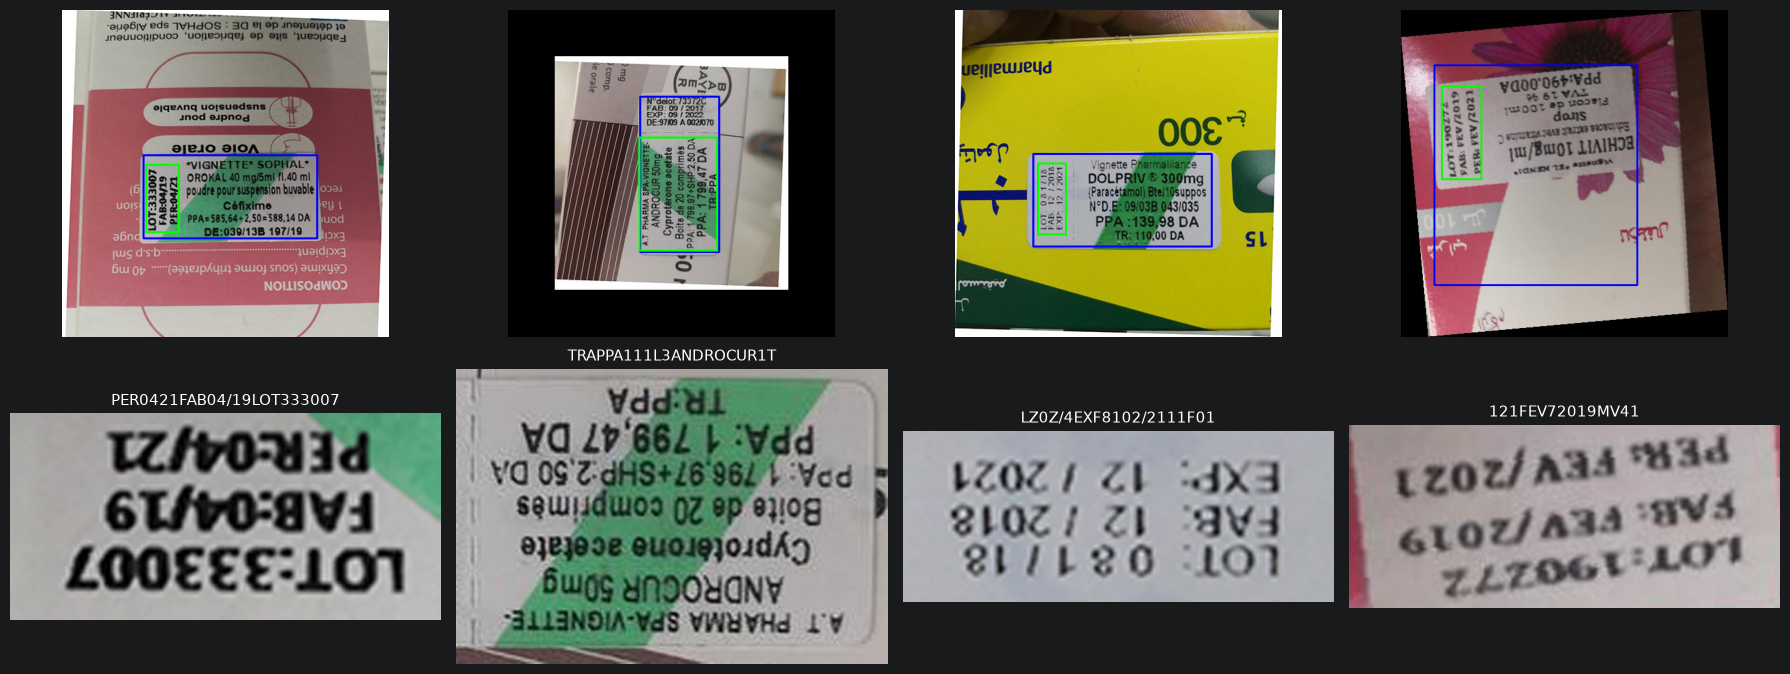

In [51]:
# 8) Cek visual tanpa label: kotak YOLO pada gambar (atas) dan crop + teks hasil OCR (bawah)
show = [i for i in ids if ocr_cache.get(i, {}).get('src') == 'crop']
if not show:
    print("Belum ada crop untuk ditampilkan (MODE='full' atau semua memakai OCR cadangan).")
else:
    sample_ids = random.sample(show, min(4, len(show)))
    fig, axes = plt.subplots(2, len(sample_ids), figsize=(4.5 * len(sample_ids), 7), squeeze=False)
    for k, img_id in enumerate(sample_ids):
        img = cv2.imread(path_of[img_id])
        t = max(2, img.shape[1] // 300)
        for d in globals().get('dets_cache', {}).get(img_id, []):
            if d['conf'] >= ENTETE_MIN_CONF:
                x1, y1, x2, y2 = map(int, d['xyxy'])
                cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0) if d['cls'] == 0 else (255, 0, 0), t)
        axes[0, k].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[0, k].axis('off')
        crop = cv2.imread(os.path.join(CROP_DIR, os.path.splitext(img_id)[0] + '.png'))
        if crop is not None:
            axes[1, k].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        axes[1, k].set_title(final_text(ocr_cache[img_id]), fontsize=11); axes[1, k].axis('off')
    plt.tight_layout(); plt.show()